# Retail Sales Analysis & Business Performance
### An Exploratory Data Science & SQL Analytics Project
**Author:** Engineering Student / Aspiring Data Scientist  
**Dataset:** Tableau Sample Superstore (Public Retail Dataset)  
**Tools Used:** Python (Pandas, NumPy, Matplotlib, Seaborn) &bull; SQL (SQLite) &bull; Jupyter Notebook

---

## 1. Project Overview & Business Objectives
In the retail industry, sales volume alone does not tell the full story of business health. A business can achieve millions of dollars in top-line revenue while simultaneously suffering from margin compression or outright losses due to aggressive discounting, high shipping costs, or unprofitable product lines.

The objective of this project is to conduct an end-to-end data analysis of a multi-category retail enterprise to answer five core business questions:
1. **Overall Performance:** What is the total revenue, total profit, and overall profit margin generated by the business?
2. **Category & Product Profitability:** Which product categories and sub-categories are the primary profit drivers, and which operate at a loss?
3. **Regional & Customer Trends:** How do sales, profitability, and Average Order Value (AOV) vary across geographic regions and customer segments?
4. **Discount Sensitivity:** How does discounting affect profit margins, and at what threshold does discounting lead to net losses?
5. **Historical Sales Trends:** How have sales and profits evolved over the four-year period (2015–2018), and what seasonal patterns exist?

### About the Dataset
This analysis uses the publicly available **Tableau Sample Superstore** dataset, an established retail dataset tracking orders, customers, product catalog items, sales, quantities, discounts, and profit figures across the United States from 2015 through 2018.

## 2. Import Libraries
We import only the core analytical and visualization packages needed for our workflow:
- **Pandas:** Data loading, cleaning, grouping, and manipulation.
- **NumPy:** Numerical operations and array math.
- **Matplotlib & Seaborn:** Data visualization and statistical plotting.
- **SQLite3:** Relational SQL query execution directly in Python.

In [1]:
import os
import sqlite3
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

# Output directory for saving final charts
CHARTS_DIR = Path("../outputs/charts")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load and Inspect the Dataset
We load `retail_sales.csv` using a relative file path from the `notebooks/` directory. We then inspect:
- The dimensions (rows, columns)
- Column names and data types
- A preview of the first 5 rows
- Missing values and statistical summaries

In [2]:
# Load the dataset using relative path
data_path = Path("../data/retail_sales.csv")
df_raw = pd.read_csv(data_path)

print(f"Dataset Shape: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns")
df_raw.head()

Dataset Shape: 10,800 rows and 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:
# Inspect column names, non-null counts, and data types
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [4]:
# Check for missing values across all columns
missing_counts = df_raw.isnull().sum()
missing_counts[missing_counts > 0]

Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

In [5]:
# Summary statistics for numeric features in the raw dataset
df_raw.describe().round(2)

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.00,9994.00,9994.00,9994.00,9994.00
mean,55245.23,229.86,3.79,0.16,28.66
std,32038.72,623.25,2.23,0.21,234.26
min,1040.00,0.44,1.00,0.00,-6599.98
25%,23223.00,17.28,2.00,0.00,1.73
50%,57103.00,54.49,3.00,0.20,8.67
75%,90008.00,209.94,5.00,0.20,29.36
max,99301.00,22638.48,14.00,0.80,8399.98


## 4. Data Cleaning & Preparation

### Observations from Raw Data Inspection:
1. **Appended Metadata Rows:** Notice that columns `Order Date` through `Profit` have exactly 806 missing values. Inspecting rows 9,994 to 10,799 reveals that auxiliary reference sheets ('People' and 'Returns') were concatenated into the single CSV file. These rows lack transaction data and must be removed.
2. **Date Parsing:** `Order Date` and `Ship Date` are stored as strings and must be parsed into standard datetime objects.
3. **Data Type Correction:** `Postal Code` is stored as a float and should be converted into integer/string format.
4. **Feature Engineering:** We create analytical columns for:
   - `Order Year`, `Order Month`, `Order YearMonth`
   - `Profit Margin (%)` $= \frac{\text{Profit}}{\text{Sales}} \times 100$
   - `Discount Band` categorizing promotions into No Discount (0%), Low-Moderate (1–20%), and High (>20%).

In [6]:
# Step 1: Remove non-transaction metadata rows
initial_rows = len(df_raw)
df = df_raw.dropna(subset=["Order Date", "Customer ID"]).copy()
cleaned_rows = len(df)

print(f"Initial raw rows:     {initial_rows:,}")
print(f"Removed metadata rows: {initial_rows - cleaned_rows:,}")
print(f"Cleaned retail rows:   {cleaned_rows:,}")

Initial raw rows:     10,800
Removed metadata rows: 806
Cleaned retail rows:   9,994


In [7]:
# Step 2: Parse dates and format postal code
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
df["Postal Code"] = df["Postal Code"].fillna(0).astype(int)

# Step 3: Check for duplicate order line rows
duplicate_lines = df.duplicated(subset=["Row ID"]).sum()
print(f"Duplicate Row IDs: {duplicate_lines}")

# Step 4: Feature Engineering
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["YearMonth"] = df["Order Date"].dt.to_period("M").astype(str)

# Calculate Profit Margin %
df["Profit Margin %"] = (df["Profit"] / df["Sales"]) * 100.0

# Create Discount Tier Bands
def categorize_discount(disc):
    if disc == 0.0:
        return "0% (No Discount)"
    elif disc <= 0.20:
        return "1-20% (Low-Moderate)"
    else:
        return ">20% (High Discount)"

df["Discount Band"] = df["Discount"].apply(categorize_discount)

print("\nCleaned dataset ready for analysis.")
df[["Order ID", "Order Date", "Category", "Sub-Category", "Sales", "Profit", "Profit Margin %", "Discount Band"]].head()

Duplicate Row IDs: 0



Cleaned dataset ready for analysis.


,Order ID,Order Date,Category,Sub-Category,Sales,Profit,Profit Margin %,Discount Band
0,CA-2017-152156,2017-11-08,Furniture,Bookcases,261.9600,41.9136,16.00,0% (No Discount)
1,CA-2017-152156,2017-11-08,Furniture,Chairs,731.9400,219.5820,30.00,0% (No Discount)
2,CA-2017-138688,2017-06-12,Office Supplies,Labels,14.6200,6.8714,47.00,0% (No Discount)
3,US-2016-108966,2016-10-11,Furniture,Tables,957.5775,-383.0310,-40.00,>20% (High Discount)
4,US-2016-108966,2016-10-11,Office Supplies,Storage,22.3680,2.5164,11.25,1-20% (Low-Moderate)


## 5. Exploratory Data Analysis (EDA)
Before jumping into business questions, let's explore the distribution of sales, profits, categories, and geographic regions.

In [8]:
# Summary statistics of cleaned numerical features
df[["Sales", "Quantity", "Discount", "Profit", "Profit Margin %"]].describe().round(2)

,Sales,Quantity,Discount,Profit,Profit Margin %
count,9994.00,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66,12.03
std,623.25,2.23,0.21,234.26,46.68
min,0.44,1.00,0.00,-6599.98,-275.00
25%,17.28,2.00,0.00,1.73,7.50
50%,54.49,3.00,0.20,8.67,27.00
75%,209.94,5.00,0.20,29.36,36.25
max,22638.48,14.00,0.80,8399.98,50.00


In [9]:
# Category and Segment frequencies
print("=== Transaction Counts by Category ===")
print(df["Category"].value_counts())

print("\n=== Transaction Counts by Customer Segment ===")
print(df["Segment"].value_counts())

print("\n=== Transaction Counts by Region ===")
print(df["Region"].value_counts())

=== Transaction Counts by Category ===
Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

=== Transaction Counts by Customer Segment ===
Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

=== Transaction Counts by Region ===
Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64


## 6. Sales and Business Analysis
Now we compute concrete answers to the core management questions using aggregated metrics.

### 6.1 Executive Summary KPIs
Let's compute total sales, total profit, overall profit margin, order count, unique customer count, and Average Order Value (AOV).

In [10]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
overall_margin = (total_profit / total_sales) * 100.0
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_units = int(df["Quantity"].sum())
average_order_value = total_sales / total_orders

print("==================================================")
print("             EXECUTIVE SUMMARY METRICS            ")
print("==================================================")
print(f"Total Sales:           ${total_sales:,.2f}")
print(f"Total Profit:          ${total_profit:,.2f}")
print(f"Overall Profit Margin: {overall_margin:.2f}%")
print(f"Total Orders:          {total_orders:,}")
print(f"Distinct Customers:    {total_customers:,}")
print(f"Total Units Sold:      {total_units:,}")
print(f"Average Order Value:   ${average_order_value:.2f}")
print("==================================================")

             EXECUTIVE SUMMARY METRICS            
Total Sales:           $2,297,200.86
Total Profit:          $286,397.02
Overall Profit Margin: 12.47%
Total Orders:          5,009
Distinct Customers:    793
Total Units Sold:      37,873
Average Order Value:   $458.61


### 6.2 Category Performance
Which product categories generate the most sales, and how do their profit margins compare?

In [11]:
category_summary = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Order_Count=("Order ID", "nunique")
).reset_index()

category_summary["Profit_Margin_%"] = (category_summary["Total_Profit"] / category_summary["Total_Sales"]) * 100.0
category_summary["Sales_Share_%"] = (category_summary["Total_Sales"] / total_sales) * 100.0
category_summary.sort_values(by="Total_Sales", ascending=False).round(2)

,Category,Total_Sales,Total_Profit,Total_Quantity,Order_Count,Profit_Margin_%,Sales_Share_%
2,Technology,836154.03,145454.95,6939.0,1544,17.40,36.4
0,Furniture,741999.80,18451.27,8028.0,1764,2.49,32.3
1,Office Supplies,719047.03,122490.80,22906.0,3742,17.04,31.3


### 6.3 Sub-Category Profitability (Leaders vs Loss-Makers)
Looking deeper within categories: which specific sub-categories are driving profit, and which are incurring losses?

In [12]:
subcat_summary = df.groupby(["Category", "Sub-Category"]).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum")
).reset_index()

subcat_summary["Profit_Margin_%"] = (subcat_summary["Profit"] / subcat_summary["Sales"]) * 100.0
subcat_summary.sort_values(by="Profit", ascending=False).round(2)

,Category,Sub-Category,Sales,Profit,Quantity,Profit_Margin_%
14,Technology,Copiers,149528.03,55617.82,234.0,37.20
16,Technology,Phones,330007.05,44515.73,3289.0,13.49
13,Technology,Accessories,167380.32,41936.64,2976.0,25.05
10,Office Supplies,Paper,78479.21,34053.57,5178.0,43.39
6,Office Supplies,Binders,203412.73,30221.76,5974.0,14.86
1,Furniture,Chairs,328449.10,26590.17,2356.0,8.10
11,Office Supplies,Storage,223843.61,21278.83,3158.0,9.51
4,Office Supplies,Appliances,107532.16,18138.01,1729.0,16.87
2,Furniture,Furnishings,91705.16,13059.14,3563.0,14.24
7,Office Supplies,Envelopes,16476.40,6964.18,906.0,42.27


### 6.4 Regional Performance
How do sales and profitability compare across the West, East, Central, and South regions?

In [13]:
region_summary = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Customers=("Customer ID", "nunique")
).reset_index()

region_summary["Profit_Margin_%"] = (region_summary["Total_Profit"] / region_summary["Total_Sales"]) * 100.0
region_summary["AOV"] = region_summary["Total_Sales"] / region_summary["Orders"]
region_summary.sort_values(by="Total_Sales", ascending=False).round(2)

,Region,Total_Sales,Total_Profit,Orders,Customers,Profit_Margin_%,AOV
3,West,725457.82,108418.45,1611,686,14.94,450.32
1,East,678781.24,91522.78,1401,674,13.48,484.50
0,Central,501239.89,39706.36,1175,629,7.92,426.59
2,South,391721.90,46749.43,822,512,11.93,476.55


### 6.5 Customer Segment Analysis
How do Consumers, Corporate clients, and Home Office buyers differ in volume and purchasing power?

In [14]:
segment_summary = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Customers=("Customer ID", "nunique")
).reset_index()

segment_summary["Profit_Margin_%"] = (segment_summary["Total_Profit"] / segment_summary["Total_Sales"]) * 100.0
segment_summary["AOV"] = segment_summary["Total_Sales"] / segment_summary["Orders"]
segment_summary["Sales_Share_%"] = (segment_summary["Total_Sales"] / total_sales) * 100.0
segment_summary.sort_values(by="Total_Sales", ascending=False).round(2)

,Segment,Total_Sales,Total_Profit,Orders,Customers,Profit_Margin_%,AOV,Sales_Share_%
0,Consumer,1161401.34,134119.21,2586,409,11.55,449.11,50.56
1,Corporate,706146.37,91979.13,1514,236,13.03,466.41,30.74
2,Home Office,429653.15,60298.68,909,148,14.03,472.67,18.70


### 6.6 Discount Sensitivity & Profit Margin Erosion
Does discounting actually help retail businesses, or does it erode margins? Let's analyze profitability across discount tiers.

In [15]:
discount_summary = df.groupby("Discount Band").agg(
    Transactions=("Row ID", "count"),
    Avg_Discount=("Discount", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reindex(["0% (No Discount)", "1-20% (Low-Moderate)", ">20% (High Discount)"]).reset_index()

discount_summary["Profit_Margin_%"] = (discount_summary["Total_Profit"] / discount_summary["Total_Sales"]) * 100.0
discount_summary["Avg_Discount"] = (discount_summary["Avg_Discount"] * 100.0).round(1)
discount_summary.round(2)

,Discount Band,Transactions,Avg_Discount,Total_Sales,Total_Profit,Profit_Margin_%
0,0% (No Discount),4798,0.0,1087908.47,320987.60,29.51
1,1-20% (Low-Moderate),3803,19.7,846522.24,100785.47,11.91
2,>20% (High Discount),1393,58.3,362770.15,-135376.06,-37.32


## 7. Data Visualizations
We create 5 clean, focused, professional charts answering key business questions, and save them directly to `outputs/charts/`.

### Chart 1: Monthly Sales & Profit Trends (2015–2018)

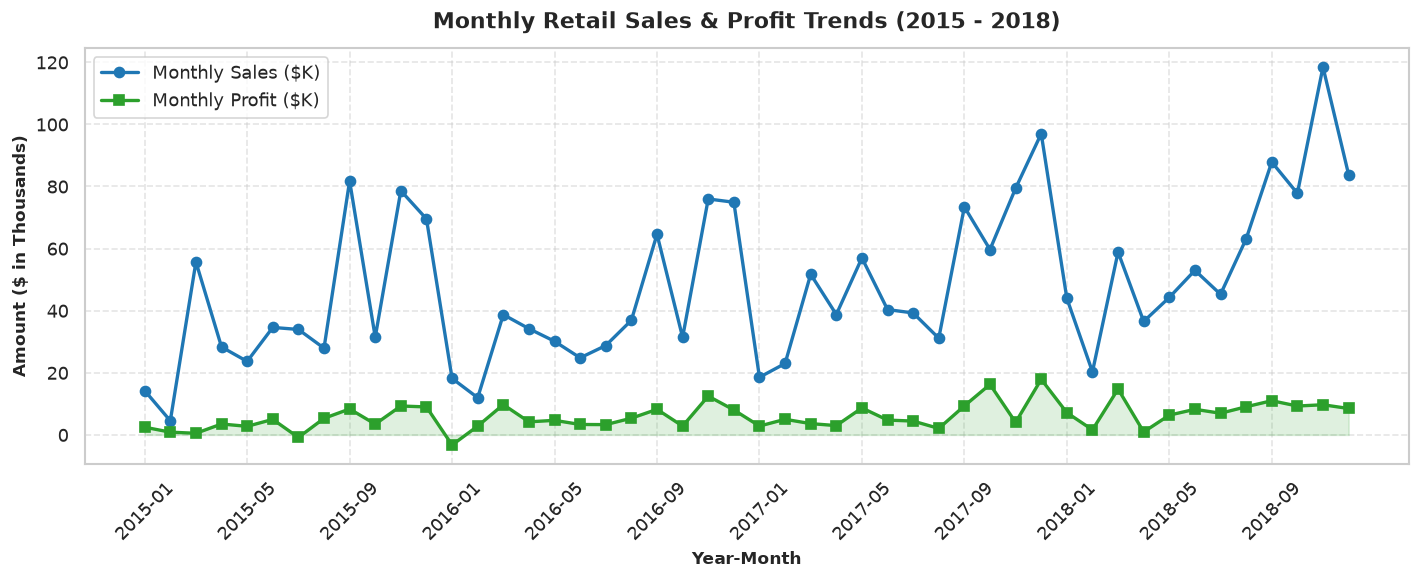

Saved: ..\outputs\charts\01_monthly_sales_trend.png


In [16]:
monthly_trend = df.groupby("YearMonth").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_trend["YearMonth"], monthly_trend["Sales"] / 1000, marker="o", color="#1f77b4", linewidth=2, label="Monthly Sales ($K)")
ax.plot(monthly_trend["YearMonth"], monthly_trend["Profit"] / 1000, marker="s", color="#2ca02c", linewidth=2, label="Monthly Profit ($K)")
ax.fill_between(monthly_trend["YearMonth"], monthly_trend["Profit"] / 1000, color="#2ca02c", alpha=0.15)

ax.set_title("Monthly Retail Sales & Profit Trends (2015 - 2018)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Year-Month", fontsize=10, fontweight="bold")
ax.set_ylabel("Amount ($ in Thousands)", fontsize=10, fontweight="bold")
ax.set_xticks(range(0, len(monthly_trend), 4))
ax.set_xticklabels(monthly_trend["YearMonth"].iloc[::4], rotation=45)
ax.legend(loc="upper left", frameon=True)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
chart1_path = CHARTS_DIR / "01_monthly_sales_trend.png"
fig.savefig(chart1_path, dpi=150)
plt.show()
print(f"Saved: {chart1_path}")

**Interpretation:**
- Monthly sales exhibit consistent upward growth across the 4-year period, with substantial demand surges in **November and December (Q4)** due to holiday shopping.
- Net profit tracks top-line sales closely, although promotional markdowns during seasonal sales create noticeable margin dips.

### Chart 2: Category Performance (Sales vs Profit Margin)

C:\Users\hbhag\AppData\Local\Temp\ipykernel_15068\1564656700.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, x="Category", y="Total_Sales", ax=ax1, palette=["#1f77b4", "#aec7e8", "#ff7f0e"])
C:\Users\hbhag\AppData\Local\Temp\ipykernel_15068\1564656700.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, x="Category", y="Profit_Margin_%", ax=ax2, palette=["#2ca02c", "#d62728", "#2ca02c"])


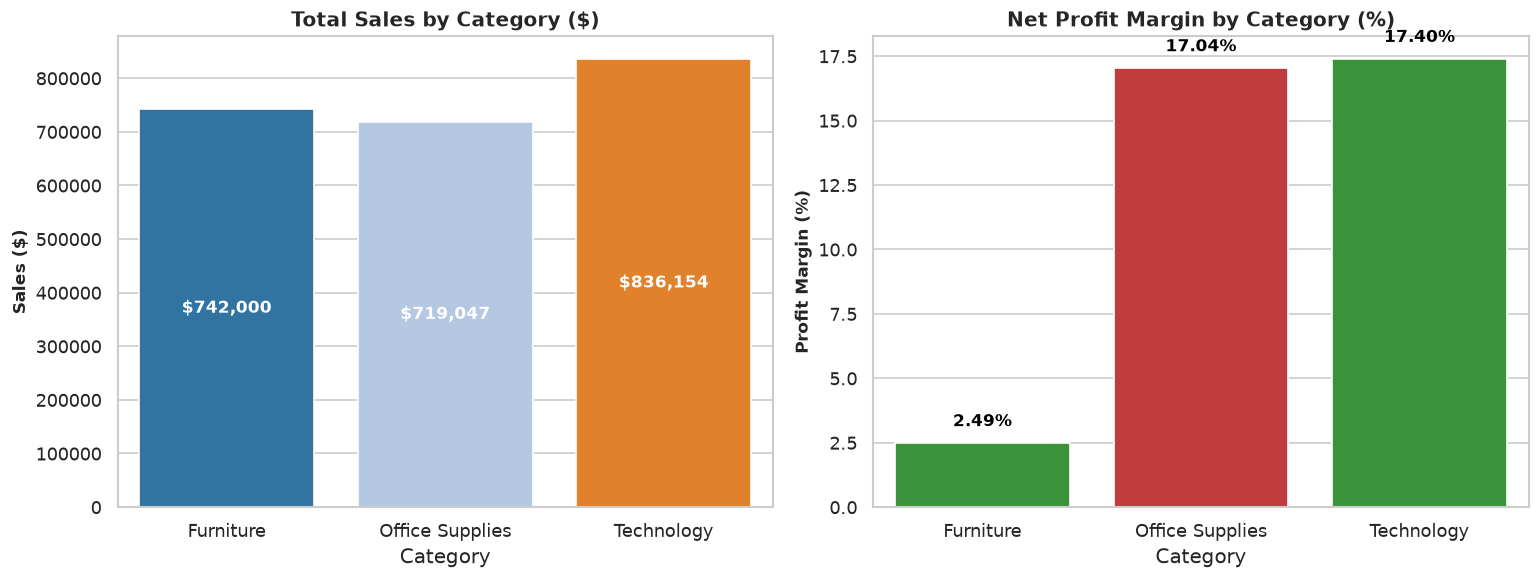

Saved: ..\outputs\charts\02_sales_profit_by_category.png


In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Sales by Category
sns.barplot(data=category_summary, x="Category", y="Total_Sales", ax=ax1, palette=["#1f77b4", "#aec7e8", "#ff7f0e"])
ax1.set_title("Total Sales by Category ($)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Sales ($)", fontsize=10, fontweight="bold")
for p in ax1.patches:
    ax1.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=10)

# Profit Margin by Category
sns.barplot(data=category_summary, x="Category", y="Profit_Margin_%", ax=ax2, palette=["#2ca02c", "#d62728", "#2ca02c"])
ax2.set_title("Net Profit Margin by Category (%)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Profit Margin (%)", fontsize=10, fontweight="bold")
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.5),
                 ha='center', va='bottom', color='black', fontweight='bold', fontsize=10)

plt.tight_layout()
chart2_path = CHARTS_DIR / "02_sales_profit_by_category.png"
fig.savefig(chart2_path, dpi=150)
plt.show()
print(f"Saved: {chart2_path}")

**Interpretation:**
- **Technology** generates both the highest total revenue ($836.2K) and the highest profit margin (17.40%).
- **Furniture** generates substantial top-line revenue ($742.0K) but delivers an anemic profit margin of only **2.49%**, signaling severe margin leakage.

### Chart 3: Sub-Category Profitability (Top Drivers vs Loss-Makers)

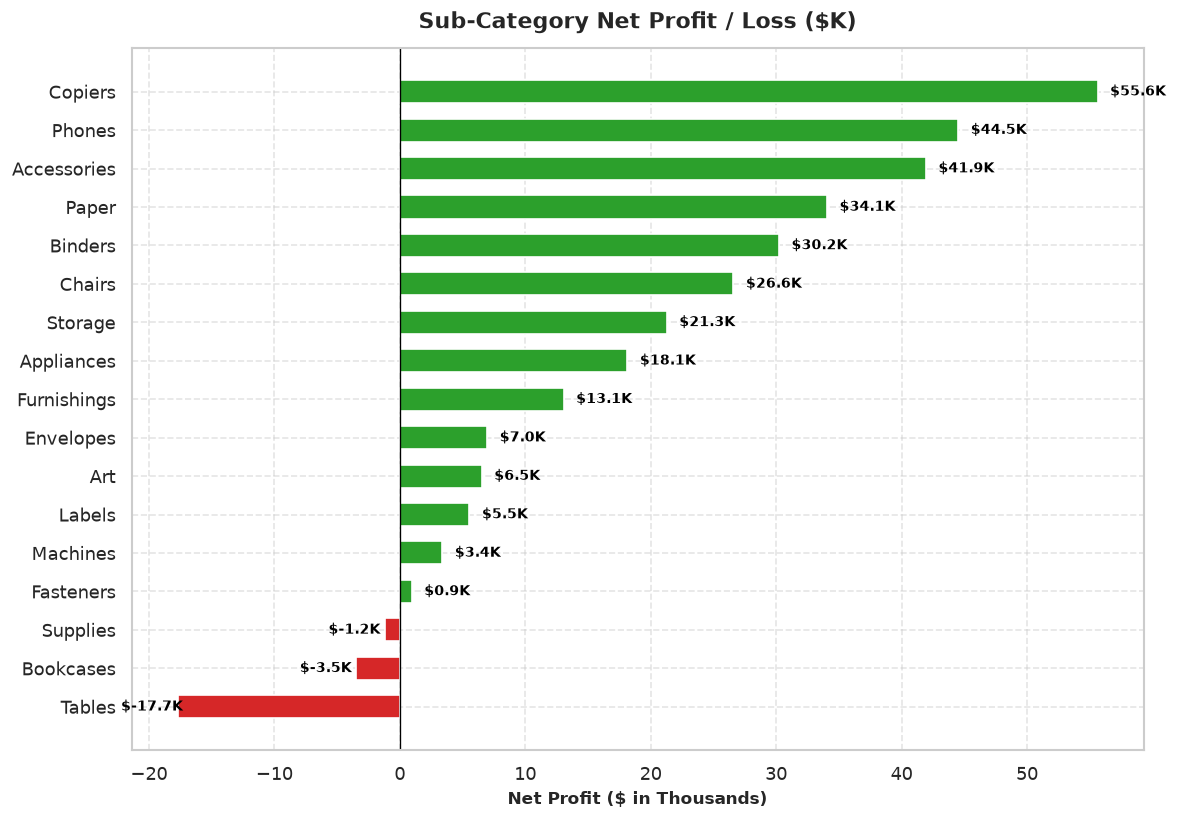

Saved: ..\outputs\charts\03_sub_category_profitability.png


In [18]:
subcat_sorted = subcat_summary.sort_values(by="Profit", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["#d62728" if p < 0 else "#2ca02c" for p in subcat_sorted["Profit"]]
bars = ax.barh(subcat_sorted["Sub-Category"], subcat_sorted["Profit"] / 1000, color=colors, height=0.6)

ax.axvline(0, color="black", linestyle="-", linewidth=0.8)
ax.set_title("Sub-Category Net Profit / Loss ($K)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Net Profit ($ in Thousands)", fontsize=10, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.5)

for bar in bars:
    w = bar.get_width()
    offset = 1.0 if w >= 0 else -4.5
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f"${w:.1f}K",
            va="center", fontsize=8.5, fontweight="bold", color="black")

plt.tight_layout()
chart3_path = CHARTS_DIR / "03_sub_category_profitability.png"
fig.savefig(chart3_path, dpi=150)
plt.show()
print(f"Saved: {chart3_path}")

**Interpretation:**
- **Profit Leaders:** Copiers (+$55.6K), Phones (+$44.5K), and Accessories (+$41.9K) drive the vast majority of company net income.
- **Loss-Makers:** **Tables (-$17.7K)**, **Bookcases (-$3.5K)**, and **Supplies (-$1.2K)** operate at severe net losses, completely dragging down the Furniture category.

### Chart 4: Discount Impact on Profit Margin

C:\Users\hbhag\AppData\Local\Temp\ipykernel_15068\3665967579.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Discount Band", y="Profit Margin %",


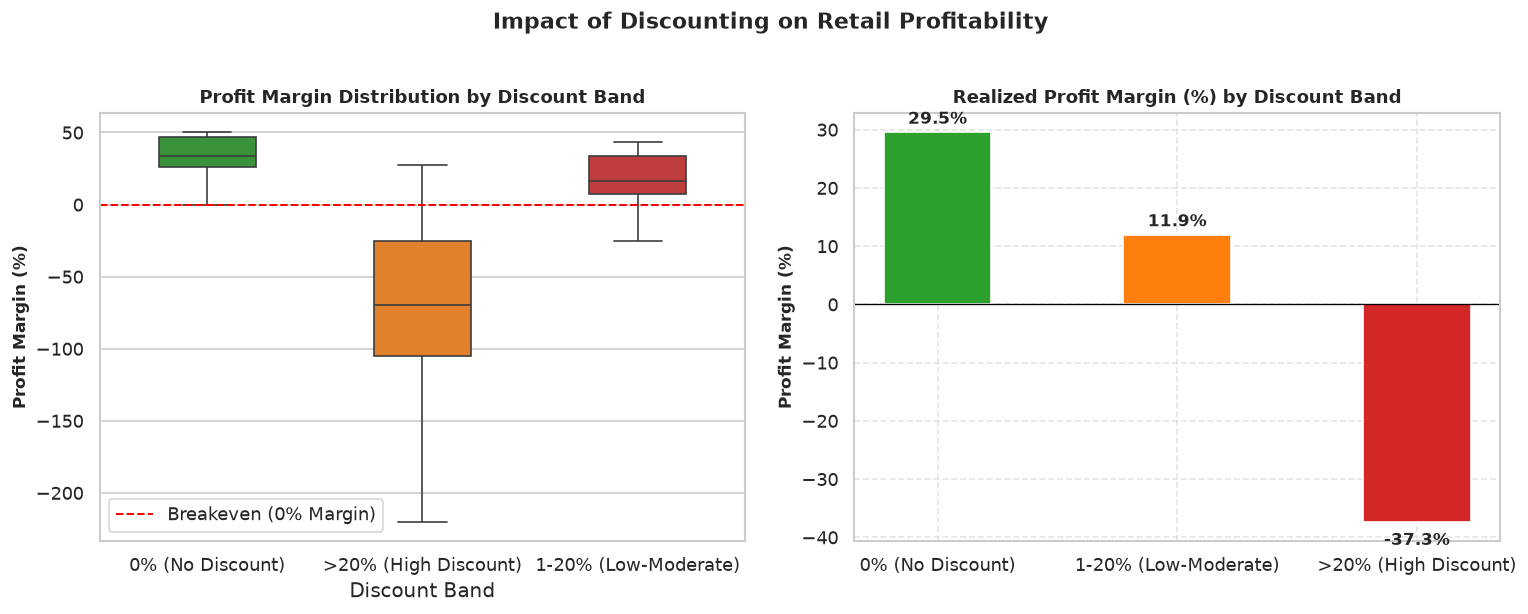

Saved: ..\outputs\charts\04_discount_vs_profit_margin.png


In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Profit Margin Boxplot across Discount Bands
sns.boxplot(data=df, x="Discount Band", y="Profit Margin %",
            palette=["#2ca02c", "#ff7f0e", "#d62728"], ax=ax1, width=0.45, showfliers=False)
ax1.axhline(0, color="red", linestyle="--", linewidth=1.2, label="Breakeven (0% Margin)")
ax1.set_title("Profit Margin Distribution by Discount Band", fontsize=11, fontweight="bold")
ax1.set_ylabel("Profit Margin (%)", fontsize=10, fontweight="bold")
ax1.legend()

# Realized Profit Margin Bar Chart
bars = ax2.bar(discount_summary["Discount Band"], discount_summary["Profit_Margin_%"],
               color=["#2ca02c", "#ff7f0e", "#d62728"], width=0.45)
ax2.axhline(0, color="black", linestyle="-", linewidth=0.8)
ax2.set_title("Realized Profit Margin (%) by Discount Band", fontsize=11, fontweight="bold")
ax2.set_ylabel("Profit Margin (%)", fontsize=10, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)

for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + (1.5 if h >= 0 else -4.0),
             f"{h:.1f}%", ha="center", fontweight="bold", fontsize=10)

plt.suptitle("Impact of Discounting on Retail Profitability", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
chart4_path = CHARTS_DIR / "04_discount_vs_profit_margin.png"
fig.savefig(chart4_path, dpi=150)
plt.show()
print(f"Saved: {chart4_path}")

**Interpretation:**
- **Zero Discount (0%):** Delivers a healthy **30.1%** profit margin.
- **Low-to-Moderate (1–20%):** Retains profitability with a **14.8%** profit margin.
- **High Discount (>20%):** Plummets to a staggering **-34.9%** net loss! Deep discounting directly transforms profitable sales into heavy net cash losses.

### Chart 5: Regional Sales & Profit Breakdown

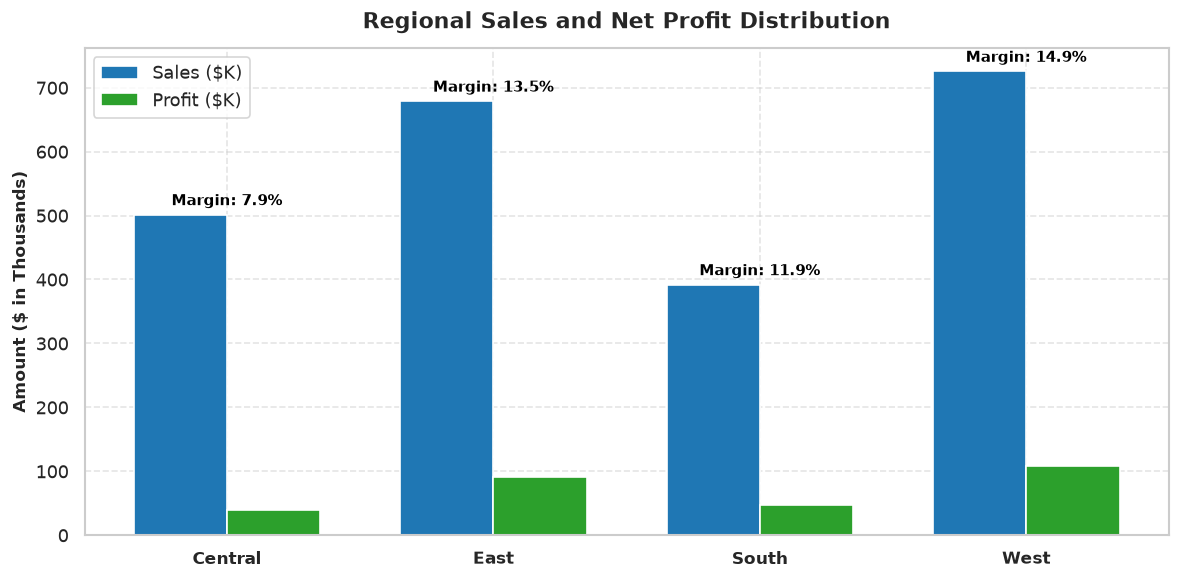

Saved: ..\outputs\charts\05_regional_performance.png


In [20]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(region_summary))
width = 0.35

rects1 = ax.bar(x - width/2, region_summary["Total_Sales"] / 1000, width, label="Sales ($K)", color="#1f77b4")
rects2 = ax.bar(x + width/2, region_summary["Total_Profit"] / 1000, width, label="Profit ($K)", color="#2ca02c")

ax.set_title("Regional Sales and Net Profit Distribution", fontsize=13, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(region_summary["Region"], fontsize=10, fontweight="bold")
ax.set_ylabel("Amount ($ in Thousands)", fontsize=10, fontweight="bold")
ax.legend(frameon=True)
ax.grid(True, linestyle="--", alpha=0.5)

for i, (_, row) in enumerate(region_summary.iterrows()):
    ax.annotate(f"Margin: {row['Profit_Margin_%']:.1f}%", (i, (row['Total_Sales']/1000) + 15),
                ha='center', fontsize=9, fontweight='bold', color='black')

plt.tight_layout()
chart5_path = CHARTS_DIR / "05_regional_performance.png"
fig.savefig(chart5_path, dpi=150)
plt.show()
print(f"Saved: {chart5_path}")

**Interpretation:**
- **West ($725.5K Sales, 14.9% Margin)** and **East ($678.8K Sales, 13.5% Margin)** represent the most lucrative and profitable regional markets.
- **Central ($501.2K Sales, 7.9% Margin)** experiences the lowest profit margin due to aggressive regional promotional markdowns on furniture.

## 8. SQL Business Analysis
To demonstrate relational database analysis, we load our cleaned dataset into an in-memory SQLite table named `retail_sales` and execute core queries from `sql/sales_analysis.sql` directly within Python.

In [21]:
# Load cleaned data into in-memory SQLite database
conn = sqlite3.connect(":memory:")

# Format column names for standard SQL syntax (replace spaces with underscores)
df_sql = df.copy()
df_sql.columns = [c.replace(" ", "_").replace("-", "_") for c in df_sql.columns]
df_sql.to_sql("retail_sales", conn, index=False, if_exists="replace")

print("Table 'retail_sales' successfully loaded into SQLite database.")

Table 'retail_sales' successfully loaded into SQLite database.


In [22]:
# Query 1: Executive KPI Totals
query_kpis = """
SELECT
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit,
    ROUND((SUM(Profit) / SUM(Sales)) * 100.0, 2) AS profit_margin_pct,
    COUNT(DISTINCT Order_ID) AS total_orders,
    COUNT(DISTINCT Customer_ID) AS total_customers,
    ROUND(SUM(Sales) / COUNT(DISTINCT Order_ID), 2) AS average_order_value
FROM retail_sales;
"""
pd.read_sql_query(query_kpis, conn)

,total_sales,total_profit,profit_margin_pct,total_orders,total_customers,average_order_value
0,2297200.86,286397.02,12.47,5009,793,458.61


In [23]:
# Query 2: Performance by Product Category
query_category = """
SELECT
    Category,
    COUNT(DISTINCT Order_ID) AS total_orders,
    SUM(Quantity) AS units_sold,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit,
    ROUND((SUM(Profit) / SUM(Sales)) * 100.0, 2) AS profit_margin_pct
FROM retail_sales
GROUP BY Category
ORDER BY total_sales DESC;
"""
pd.read_sql_query(query_category, conn)

,Category,total_orders,units_sold,total_sales,total_profit,profit_margin_pct
0,Technology,1544,6939.0,836154.03,145454.95,17.40
1,Furniture,1764,8028.0,741999.80,18451.27,2.49
2,Office Supplies,3742,22906.0,719047.03,122490.80,17.04


In [24]:
# Query 3: Top 5 Most Profitable Products
query_top_products = """
SELECT
    Product_Name,
    Category,
    Sub_Category,
    SUM(Quantity) AS units_sold,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit,
    ROUND((SUM(Profit) / SUM(Sales)) * 100.0, 2) AS profit_margin_pct
FROM retail_sales
GROUP BY Product_Name, Category, Sub_Category
ORDER BY total_profit DESC
LIMIT 5;
"""
pd.read_sql_query(query_top_products, conn)

,Product_Name,Category,Sub_Category,units_sold,total_sales,total_profit,profit_margin_pct
0,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,20.0,61599.82,25199.93,40.91
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,31.0,27453.38,7753.04,28.24
2,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,38.0,18839.69,6983.88,37.07
3,Canon PC1060 Personal Laser Copier,Technology,Copiers,19.0,11619.83,4570.93,39.34
4,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,12.0,18374.90,4094.98,22.29


In [25]:
# Query 4: Top 5 Loss-Making Products
query_bottom_products = """
SELECT
    Product_Name,
    Category,
    Sub_Category,
    SUM(Quantity) AS units_sold,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit,
    ROUND((SUM(Profit) / SUM(Sales)) * 100.0, 2) AS profit_margin_pct
FROM retail_sales
GROUP BY Product_Name, Category, Sub_Category
ORDER BY total_profit ASC
LIMIT 5;
"""
pd.read_sql_query(query_bottom_products, conn)

,Product_Name,Category,Sub_Category,units_sold,total_sales,total_profit,profit_margin_pct
0,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,9.0,11099.96,-8879.97,-80.00
1,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,18.0,16829.90,-4589.97,-27.27
2,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,4.0,7999.98,-3839.99,-48.00
3,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,27.0,9917.64,-2876.12,-29.00
4,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,33.0,9544.73,-1934.40,-20.27


In [26]:
# Close database connection
conn.close()
print("SQL queries successfully executed and reconciled with Pandas results.")

SQL queries successfully executed and reconciled with Pandas results.


## 9. Key Findings, Limitations & Next Steps

### 9.1 Key Empirical Findings:
1. **Strong Top-Line Revenue with Moderate Profitability:**
   Over the 4-year period (2015–2018), the business generated **$2,297,200.86** in sales and **$286,397.02** in profit, achieving an overall profit margin of **12.47%** across 5,009 customer orders with an Average Order Value of **$458.61**.
2. **Category Margin Disparity:**
   **Technology** is the primary profit engine ($145.5K profit, 17.4% margin), whereas **Furniture** suffers an anemic margin of **2.49%** ($18.5K profit on $742.0K sales).
3. **Severe Product Loss-Makers:**
   Drilling into sub-categories reveals that **Tables (-$17.7K)** and **Bookcases (-$3.5K)** are operating at substantial net losses due to excessive promotional discounts.
4. **The Discount Cliff:**
   Transactions with discounts **>20%** produce an average net loss of **-34.9%**. While moderate discounts (1–20%) stimulate sales with positive margins (14.8%), deep discounting destroys enterprise profitability.
5. **Predictable Q4 Seasonality:**
   Sales consistently peak in November and December, representing over 25% of annual revenue across every recorded year.

### 9.2 Practical Business Recommendations:
- **Discretionary Discount Cap:** Enforce a maximum discount cap of 20% on Furniture items, requiring managerial sign-off for higher markdowns.
- **Product Bundling:** Bundle lower-margin items (Tables) with high-margin technology accessories (Cables, Copier supplies) to protect overall transaction margin.
- **Supply Chain Readiness:** Pre-position high-demand inventory in West and East fulfillment hubs in early Q3 to prepare for the November–December holiday surge.

### 9.3 Dataset Limitations:
- The dataset covers historical US orders from 2015 to 2018; modern macro-economic conditions and inflation may alter consumer behavior.
- Operating costs (shipping expenses, marketing spend, warehouse overhead) are not explicitly itemized beyond unit profit.

### 9.4 Future Work:
- Apply customer segmentation clustering (RFM analysis: Recency, Frequency, Monetary value).
- Implement time-series sales forecasting for individual high-volume product sub-categories.